<a href="https://colab.research.google.com/github/skarchana-ai/Machine-Learning/blob/main/Feature_Selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature Selection

Feature Selection is the process of selecting the most revelent features (columns) from a dataset while removing irrelevant, redundant or less important features.

In machine learning, feature selection helps to :

*   Improve model Performance
*   Reduce overfitting
*   Reduce training time
*   Remove unnecessary features
*   Make models simpler and easier to understand

There are three main approacges to feature selection:


1.   Filter Method
2.   Wrapper Method
3.   Embedded Method

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold,chi2,f_classif,mutual_info_classif,SelectKBest
from scipy.stats import pearsonr, spearmanr

In [ ]:
data = {
    'Study_Hours': [
        2, 3, 5, 6, 1, 7, 4, 8, 2, 6,
        3, 9, 5, 1, 7, 4, 8, 2, 6, 5
    ],

    'Attendance': [
        55, 60, 80, 90, 40, 95, 75, 98, 50, 85,
        65, 99, 82, 45, 92, 70, 96, 48, 88, 78
    ],

    'Previous_Score': [
        45, 50, 75, 85, 35, 90, 65, 95, 40, 80,
        55, 98, 72, 30, 88, 60, 94, 38, 83, 70
    ],

    'Assignment_Score': [
        50, 55, 78, 88, 30, 92, 68, 96, 45, 82,
        60, 99, 75, 35, 90, 65, 95, 40, 85, 73
    ],

    'Sleep_Hours': [
        5, 6, 7, 8, 4, 7, 6, 8, 5, 7,
        6, 8, 7, 4, 8, 6, 7, 5, 8, 7
    ],

    'Internet_Access': [
        0, 1, 1, 1, 0, 1, 1, 1, 0, 1,
        1, 1, 1, 0, 1, 1, 1, 0, 1, 1
    ],

    'Extra_Coaching': [
        0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
        0, 1, 1, 0, 1, 0, 1, 0, 1, 1
    ],

    'Pass': [
        0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
        0, 1, 1, 0, 1, 0, 1, 0, 1, 1
    ]
}

In [ ]:
df=pd.DataFrame(data)

In [ ]:
df

,Study_Hours,Attendance,Previous_Score,Assignment_Score,Sleep_Hours,Internet_Access,Extra_Coaching,Pass
0,2,55,45,50,5,0,0,0
1,3,60,50,55,6,1,0,0
2,5,80,75,78,7,1,1,1
3,6,90,85,88,8,1,1,1
4,1,40,35,30,4,0,0,0
5,7,95,90,92,7,1,1,1
6,4,75,65,68,6,1,0,1
7,8,98,95,96,8,1,1,1
8,2,50,40,45,5,0,0,0
9,6,85,80,82,7,1,1,1


Seperate Independent and Dependent Variables

In [ ]:
X=df.drop('Pass',axis=1)
y=df['Pass']

X=Independent variables(input features)

y=Dependent Variables(target/output)

In [ ]:
X

,Study_Hours,Attendance,Previous_Score,Assignment_Score,Sleep_Hours,Internet_Access,Extra_Coaching
0,2,55,45,50,5,0,0
1,3,60,50,55,6,1,0
2,5,80,75,78,7,1,1
3,6,90,85,88,8,1,1
4,1,40,35,30,4,0,0
5,7,95,90,92,7,1,1
6,4,75,65,68,6,1,0
7,8,98,95,96,8,1,1
8,2,50,40,45,5,0,0
9,6,85,80,82,7,1,1


In [ ]:
y

,Pass
0,0
1,0
2,1
3,1
4,0
5,1
6,1
7,1
8,0
9,1


# Filter Method

# 1. Varience threshold

Varience Threshold is a feature selection technique that removes features with very low varience.

Varience measures how much the values in a column differ from each other.

If a column contains almost the same value for every row, it provides very little information to the model.

sigma^2 = summation(x-x bar)^2 / n

In [ ]:
from sklearn.feature_selection import VarianceThreshold

#Create a copy of the dataset
df_variance=X.copy()

#Add a constant column
df_variance['Constant_Feature']=5

#Add a low variance column
df_variance['Low_Variance']=[
    1,1,1,1,1,1,1,1,1,1,
    1,1,1,1,1,1,1,1,1,2
]

#Create Variance Threshold object
selector=VarianceThreshold(threshold=0.1)

#Apply feature selection
selected_data=selector.fit_transform(df_variance)

In [ ]:
# Get selected column names
selected_features=df_variance.columns[
    selector.get_support()
]

print("Select Features:")
print(selected_features.tolist())

print("\n\nRemoved Features:")
print(
    df_variance.columns[
        ~selector.get_support()
        ].tolist()
)

Select Features:
['Study_Hours', 'Attendance', 'Previous_Score', 'Assignment_Score', 'Sleep_Hours', 'Internet_Access', 'Extra_Coaching']


Removed Features:
['Constant_Feature', 'Low_Variance']


# Correlation Analysis

Correlation Analysis is a statistical techinique used to identify the relationship between two or more variables.

It helps us understand whether two features are strongly related to each other.

In feature selection, correlation analysis is used to identify redundant features.

Foe example:

*   Study Hours and Assignment Score might have a strong positive relationship.
*   Attendence and Previous Score might also have a relationship.If two features contain almost the same information, we may remove one of them.

Types of Correlation:

1.   Positive
2.   Negative
3.   No Correlation

POSITIVE COORELATION

When one variable increases, the other variable also tends to increase.

NEGATIVE COORELATION

When one variable increases, the other variable tends to decrease.

NO CORRELATION

There is no clear relationship between the two variables.

Example: Student ID and Exam Marks.

When to use it?

Use Correlation analysis to identify highly correlated features and reduce redundant information in the dataset.









In [ ]:
#Calculate correlation between numerical features
correlation_matrix=X.corr()

# Visualise the Correlation Matrix

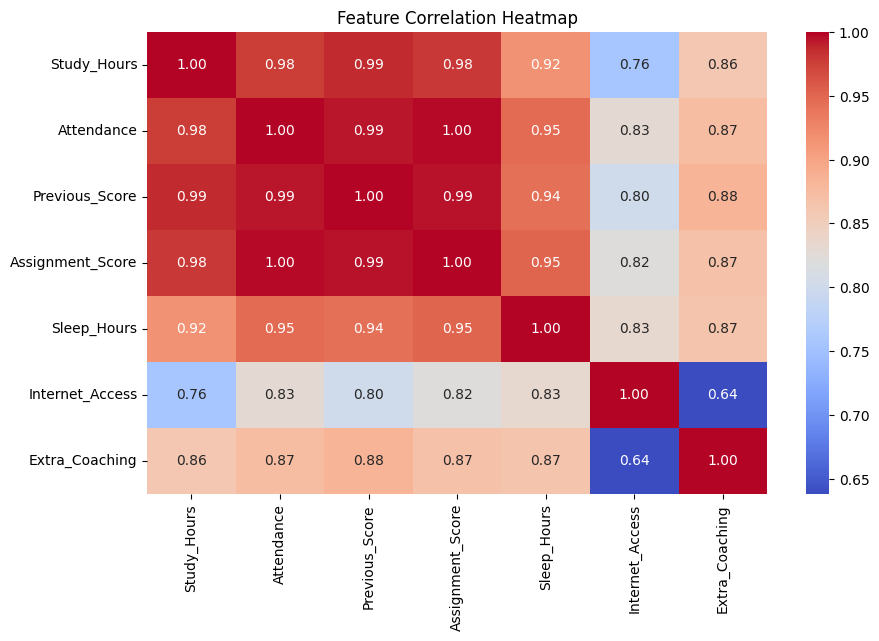

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")

plt.show()